<a href="https://colab.research.google.com/github/Giocrisrai/taller-ia-agentes-biblioteca/blob/main/notebooks/01_Taller_Practico_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

> **Ábrelo en Colab con el botón de arriba.** Una vez dentro: `Archivo` → `Guardar una copia en Drive`, para trabajar sobre tu propia copia.

# Taller Práctico 1 — Construye un agente básico con herramientas

**DUOC UC · Sistema de Bibliotecas** · Curso de IA Aplicando Agentes (nivel básico-medio) · Taller 1 de 2 · 60 min

---

En la sesión teórica vimos **qué es** un agente. Hoy lo vas a **construir** en Python y lo
vas a ver razonar: un modelo de lenguaje que decide cuándo necesita una herramienta, la pide,
recibe el resultado y recién ahí responde.

## 🎯 Antes de empezar: qué vamos a aprender hoy

### Contenidos

1. Qué es un **agente**: un modelo de lenguaje que decide cuándo usar herramientas.
2. El **mensaje de sistema** (*system prompt*): rol, alcance y formato.
3. **Herramientas** en Python con `@tool`: qué ve el modelo y qué no.
4. El agente con `create_agent` y la **traza** del ciclo ReAct: 🧠 → 🔧 → 👀 → ✅.
5. **Encadenamiento** de herramientas y una herramienta que consulta una **API real**.

### Objetivo de la sesión

Construir un agente básico con herramientas y **leer su razonamiento**, para entender en qué
se diferencia de un modelo de lenguaje solo.

### Aprendizajes esperados — al terminar podrás:

- **Explicar** por qué un modelo solo inventa datos que no tiene, y cómo una herramienta lo resuelve.
- **Escribir** una herramienta con `@tool`: nombre, descripción y argumentos.
- **Crear** un agente con `create_agent` y darle instrucciones de sistema.
- **Leer** la traza del agente e identificar qué decidió el modelo y qué ejecutó tu programa.
- **Reconocer** cuándo un agente encadena varias herramientas para responder.

> 💡 **Lo valioso de hoy no es que las celdas corran, sino entender por qué el agente hace lo
> que hace.** Con eso vas a poder reconocer dónde un agente aporta en tu propio trabajo.

### Lo que necesitas

- Saber Python básico-intermedio: funciones, diccionarios, *type hints*, f-strings.
- Tu llave gratuita de **Groq** guardada en los Secrets de Colab (era el **pre-trabajo**).
  Si no la tienes, el Paso 2 te dice cómo sacarla en 3 minutos, y mientras tanto el notebook
  sigue en **modo simulado**.

### El camino de hoy: 10 pasos

| | Paso | Qué haces | Min |
|---|---|---|---|
| 🎯 | — | Contenidos, objetivos y aprendizajes esperados | 2 |
| 🔑 | **1–3** | Instalas, cargas tu llave y te conectas al modelo | 6 |
| 💬 | **4** | Hablas con el modelo solo y cambias su *system prompt* | 8 |
| 🔧 | **5** | Escribes tu primera herramienta | 8 |
| 🤖 | **6–7** | Armas el agente y lees la traza | 12 |
| 🧪 | **8** | Lo pruebas con consultas distintas | 8 |
| 🧩 | **9** | Dos herramientas más: fechas y una API real | 14 |
| 💾 | **10** | Encuesta, cierre y guardas tu copia | 2 |
| 🎯 | **Desafíos** | Propuestos para después del taller | — |

*(60 minutos en total.)*

Cada celda de código empieza con `▶ PASO N`: así sabes siempre dónde estás.

> 🙋 **Si algo falla, levanta la mano.** No pierdas cinco minutos peleando en silencio.

---
---

# 🔑 Paso 1 · Instala las librerías

⏱️ *1 minuto*

| Librería | Para qué |
|---|---|
| `langchain` | El *framework* de agentes. Usamos su API 1.x: `create_agent` |
| `langchain-groq` | Conecta LangChain con Groq, el proveedor del modelo |

> ⚠️ **La primera vez Colab muestra** *«Warning: This notebook was not authored by Google»*,
> porque el notebook viene de GitHub. Es normal: pulsa **`Run anyway`**.

In [ ]:
# ▶ PASO 1 · Instala las librerías (unos 30 segundos).
import sys

if "google.colab" in sys.modules:
    %pip install -qU langchain langchain-groq
    print("✅ Librerías instaladas. Puedes ignorar los avisos amarillos.")
else:
    print("✅ Entorno local: se asume que las librerías ya están instaladas.")

---

# 🔑 Paso 2 · Carga tu llave

⏱️ *2 minutos*

La llave **no se escribe en el código**: vive en los **Secrets** de Colab (ícono de llave 🔑
en la barra izquierda). Si hiciste el pre-trabajo, ya está ahí.

| Secret | De dónde sale |
|---|---|
| `GROQ_API_KEY` | [console.groq.com](https://console.groq.com/) → API Keys → Create API Key (empieza por `gsk_`) |

**Son dos acciones:** crearlo con el nombre exacto **y activar el
interruptor *Notebook access***. Guardarlo sin activar el interruptor es el error nº 1.

| Lo que ves | Qué pasó | Solución |
|---|---|---|
| `❌ no encontrada` | El interruptor *Notebook access* está apagado | Actívalo y vuelve a ejecutar |
| `❌ no encontrada` con el interruptor encendido | El nombre está mal escrito | Debe ser exactamente `GROQ_API_KEY` |
| Colab pide permiso para acceder al Secret | Es normal la primera vez en cada notebook | Pulsa **Grant access** enseguida |
| `⚠️ ... todavía no tiene permiso` | Usaste *Run all* y el permiso llegó tarde | Vuelve a ejecutar los Pasos 2 y 3 |

In [ ]:
# ▶ PASO 2 · Carga tu llave desde los Secrets de Colab (o desde un .env si trabajas local).
import os

def _leer_secreto(nombre):
    try:
        from google.colab import userdata  # type: ignore
    except ImportError:                    # fuera de Colab: .env o variables del sistema
        return os.getenv(nombre, "")
    import time
    for intento in range(6):               # hasta ~1 minuto para que alcances a pulsar «Grant access»
        try:
            return userdata.get(nombre) or ""
        except Exception as e:
            if "NotFound" in type(e).__name__:
                return os.getenv(nombre, "")   # el Secret no existe (o el nombre está mal escrito)
            # NotebookAccessError o TimeoutException: Colab está pidiendo permiso y nadie ha respondido
            if intento == 0:
                print(f"⏳ {nombre}: Colab te pide permiso. Pulsa «Grant access»; espero hasta 1 minuto...")
            time.sleep(1)
    print(f"⚠️  {nombre}: sin permiso. Activa 'Notebook access' en el panel 🔑 y vuelve a ejecutar esta celda.")
    return ""

try:
    from dotenv import load_dotenv  # solo para trabajo local
    load_dotenv()
except ImportError:
    pass

valor = _leer_secreto("GROQ_API_KEY")
if valor:
    os.environ["GROQ_API_KEY"] = valor.strip()

print("GROQ_API_KEY  :", "✅ encontrada" if os.getenv("GROQ_API_KEY") else "❌ no encontrada")

---

# 🔑 Paso 3 · Conéctate al modelo

⏱️ *3 minutos*

La siguiente celda es **técnica**: puedes leerla, pero no necesitas entenderla para seguir.
Hace tres cosas:

1. **`conectar_modelo()`** prueba los proveedores en orden y se queda con el primero que responde:

   `Groq · gpt-oss-120b` → `Groq · gpt-oss-20b` → `modo simulado`

   El 20b es el plan B dentro de Groq: el cupo gratuito es **por modelo**, así que si
   agotas uno el otro sigue disponible, con la misma llave.
2. **`ejecutar(agente, pregunta)`** le envía una pregunta al agente e imprime la **traza**:
   🧠 pensamiento · 🔧 acción · 👀 observación · ✅ respuesta.
3. **`ModeloSimulado`**: un falso modelo que elige herramientas con reglas fijas. Solo
   entra si no hay ningún proveedor, para que nadie se quede fuera de la clase.

**Lo que quieres ver:** `✅ Conectado a groq · openai/gpt-oss-120b`

> 🤔 **«¿Por qué dice `openai` si usamos Groq?»** `gpt-oss-120b` es un modelo de **pesos
> abiertos** que publicó OpenAI; **Groq lo hospeda y lo ejecuta** y se descuenta de tu cupo
> de Groq. No necesitas cuenta de OpenAI.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# ▶ PASO 3 · Celda técnica: conexión al modelo (con respaldo) y visor de la traza.
#   Puedes leerla, pero no necesitas entenderla para seguir el taller.
#   Define tres cosas:  conectar_modelo()  ·  ejecutar()  ·  ModeloSimulado
# ─────────────────────────────────────────────────────────────────────────────
import json, re, textwrap, unicodedata
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage
from langchain_core.language_models.chat_models import BaseChatModel
from langchain_core.outputs import ChatGeneration, ChatResult

# Orden de preferencia. Si el primero falla (sin llave, sin cupo, caído) se prueba el siguiente.
#   Groq 120b → Groq 20b (cupo diario independiente) → modo simulado
CANDIDATOS = [
    ("groq", "openai/gpt-oss-120b"),
    ("groq", "openai/gpt-oss-20b"),
]

PROVEEDOR = "auto"   # o fuerza uno: "groq", "simulado"


def _normalizar(texto):
    texto = unicodedata.normalize("NFD", str(texto).lower())
    return "".join(c for c in texto if unicodedata.category(c) != "Mn")


class ModeloSimulado(BaseChatModel):
    """Respaldo SIN modelo de lenguaje. Elige la herramienta por palabras clave y saca los
    argumentos con expresiones regulares. No razona: solo permite seguir la clase sin llave."""

    herramientas: list = []

    @property
    def _llm_type(self):
        return "simulado"

    def bind_tools(self, tools, **kwargs):
        return ModeloSimulado(herramientas=list(tools))

    # -- utilidades -------------------------------------------------------------
    @staticmethod
    def _campos(h):
        esquema = h.get_input_schema().model_json_schema()
        return esquema.get("properties", {}), set(esquema.get("required", []))

    def _argumentos(self, h, texto):
        props, requeridos = self._campos(h)
        limpio = _normalizar(re.sub(r"\d{1,2}[-/]\d{1,2}[-/]\d{2,4}|\d{1,2}:\d{2}|[A-Za-z]-\d{3}", " ", texto))
        numeros = [int(n) for n in re.findall(r"\b\d+\b", limpio)]
        args, faltan = {}, []
        for nombre, info in props.items():
            n, tipo = _normalizar(nombre), info.get("type")
            valor = None
            if tipo == "integer":  # busca el número que va justo antes de una palabra del nombre del campo
                for trozo in n.split("_"):
                    m = re.search(r"\b(\d+)\s+(?:\w+\s+)?" + re.escape(trozo[:4]), limpio)
                    if m and int(m.group(1)) in numeros:
                        valor = int(m.group(1))
                        numeros.remove(valor)
                        break
            if valor is not None:
                pass
            elif "enum" in info:
                valor = next((op for op in info["enum"] if _normalizar(op) in _normalizar(texto)), None)
            elif "fecha" in n:
                m = re.search(r"\b(\d{1,2}[-/]\d{1,2}[-/]\d{4})\b", texto)
                valor = m.group(1).replace("/", "-") if m else None
            elif "hora" in n:
                m = re.search(r"\b(\d{1,2}:\d{2})\b", texto)
                valor = m.group(1) if m else None
            elif "codigo" in n:
                m = re.search(r"\b([A-Za-z]-?\d{3})\b", texto)
                valor = m.group(1).upper() if m else None
            elif tipo == "string":
                m = re.search(r"[«\"“']([^»\"”']+)[»\"”']", texto)
                valor = m.group(1) if m else (texto if nombre in requeridos else None)
            if valor is None and nombre in requeridos:
                faltan.append(nombre)
            elif valor is not None:
                args[nombre] = valor
        return args, faltan

    def _generate(self, messages, stop=None, run_manager=None, **kwargs):
        ultimo = messages[-1]
        if isinstance(ultimo, ToolMessage):  # ya tiene observaciones: responde con ellas
            obs = []
            for m in reversed(messages):
                if isinstance(m, ToolMessage):
                    obs.append(str(m.content))
                elif isinstance(m, HumanMessage):
                    break
            return self._msg("(modo simulado) " + " | ".join(reversed(obs)))

        pregunta = str(ultimo.content)
        p = _normalizar(pregunta)
        if "como me llamo" in p:  # una pizca de memoria para que la demo funcione sin llave
            for m in messages:
                if isinstance(m, HumanMessage):
                    hit = re.search(r"(?:me llamo|soy) (\w+)", str(m.content), re.I)
                    if hit:
                        return self._msg(f"(modo simulado) Te llamas {hit.group(1)}.")
            return self._msg("(modo simulado) No sé tu nombre.")

        if not self.herramientas:  # el modelo "a secas", sin herramientas
            return self._msg("(modo simulado) Aquí respondería el modelo de lenguaje. Sin llave no hay "
                             "modelo: conecta tu llave para ver la respuesta real.")
        vacias = {"libro", "libros", "biblioteca", "tengo", "puedo", "quiero", "cuanto", "cuantos", "cuantas", "veces", "para", "como", "quien"}
        raices = {w[:5] for w in re.findall(r"\w+", p) if len(w) > 3 and w not in vacias}
        mejor, puntaje = None, 0
        for h in self.herramientas:
            texto_h = _normalizar(h.name.replace("_", " ") + " " + (h.description or ""))
            puntos = sum(1 for r in raices if r in texto_h)
            if puntos > puntaje:
                mejor, puntaje = h, puntos
        if mejor is None:
            return self._msg("(modo simulado) No tengo una herramienta para eso.",
                             pensamiento="Ninguna herramienta coincide con las palabras de la pregunta.")
        args, faltan = self._argumentos(mejor, pregunta)
        if faltan:
            return self._msg(f"(modo simulado) Para usar {mejor.name} me falta: {', '.join(faltan)}.",
                             pensamiento=f"Elegí {mejor.name}, pero no pude deducir {faltan}.")
        return AIMessage_tool(mejor.name, args, f"Elegí {mejor.name} por {puntaje} palabras en común (regla fija, no razonamiento).")

    @staticmethod
    def _msg(texto, pensamiento=None):
        extra = {"reasoning_content": pensamiento} if pensamiento else {}
        return ChatResult(generations=[ChatGeneration(message=AIMessage(content=texto, additional_kwargs=extra))])


def AIMessage_tool(nombre, args, pensamiento):
    llamada = {"name": nombre, "args": args, "id": f"sim-{nombre}", "type": "tool_call"}
    msg = AIMessage(content="", tool_calls=[llamada], additional_kwargs={"reasoning_content": pensamiento})
    return ChatResult(generations=[ChatGeneration(message=msg)])


def _crear(proveedor, nombre_modelo):
    if proveedor == "groq":
        from langchain_groq import ChatGroq
        return ChatGroq(model=nombre_modelo, temperature=0, max_retries=4)   # reintenta solo si hay límite por minuto
    raise ValueError(proveedor)


def conectar_modelo(forzar=None):
    """Prueba los candidatos en orden con una llamada mínima y devuelve el primero que responde."""
    global PROVEEDOR_ACTIVO
    preferido = forzar or PROVEEDOR
    if preferido != "simulado":
        for proveedor, nombre in CANDIDATOS:
            if preferido not in ("auto", proveedor):
                continue
            if not os.getenv("GROQ_API_KEY"):
                continue
            try:
                m = _crear(proveedor, nombre)
                m.invoke("Responde solo: OK")
                PROVEEDOR_ACTIVO = f"{proveedor} · {nombre}"
                print(f"✅ Conectado a {PROVEEDOR_ACTIVO}")
                return m
            except Exception as e:
                print(f"⚠️  {proveedor} · {nombre} no respondió ({type(e).__name__}). Pruebo el siguiente...")
    PROVEEDOR_ACTIVO = "simulado"
    print("🟡 MODO SIMULADO: no hay ningún proveedor disponible. Puedes seguir la clase,")
    print("   pero el agente elegirá herramientas con reglas fijas, sin razonar.")
    print("   Revisa el Paso 2 (nombre del Secret y el interruptor 'Notebook access').")
    return ModeloSimulado()


def _texto(m):
    contenido = m.content
    if isinstance(contenido, list):  # algunos modelos devuelven una lista de partes
        contenido = " ".join(p.get("text", "") if isinstance(p, dict) else str(p) for p in contenido)
    return str(contenido).strip()


def _corto(texto, n=260):
    texto = " ".join(str(texto).split())
    return texto if len(texto) <= n else texto[:n] + " …"


def mostrar_traza(mensajes, pensamiento=True):
    """Imprime los mensajes como la traza del ciclo ReAct."""
    for m in mensajes:
        if isinstance(m, AIMessage):
            razon = m.additional_kwargs.get("reasoning_content")
            if pensamiento and razon:
                print("🧠 Pensamiento :", _corto(razon))
            for t in m.tool_calls:
                print(f"🔧 Acción      : {t['name']}({json.dumps(t['args'], ensure_ascii=False)})")
            if not m.tool_calls and _texto(m):
                print("✅ Respuesta   :", textwrap.fill(_texto(m), 100, subsequent_indent=" " * 16))
        elif isinstance(m, ToolMessage):
            print("👀 Observación :", _corto(m.content, 400))


def ejecutar(agente, pregunta, historial=None, pensamiento=True, max_pasos=8):
    """Envía `pregunta` al agente, imprime la traza y devuelve la conversación completa.

    historial  → lista de mensajes anteriores (la memoria). None = empezar de cero.
    max_pasos  → tope de vueltas del ciclo; evita bucles infinitos.
    """
    entrada = list(historial or []) + [HumanMessage(content=pregunta)]
    print("👤 Pregunta    :", pregunta)
    try:
        salida = agente.invoke({"messages": entrada}, config={"recursion_limit": 2 * max_pasos + 1})
    except Exception as e:
        nombre, texto = type(e).__name__, str(e)
        print(f"❌ {nombre}: {_corto(texto, 200)}")
        if "Recursion" in nombre:
            print("   → El agente superó el tope de pasos (max_pasos). Es un límite de seguridad funcionando.")
        elif "tool_use_failed" in texto or "BadRequest" in nombre:
            print("   → El modelo armó mal la llamada a la herramienta. No es tu código: vuelve a ejecutar la celda.")
        elif "per minute" in texto:
            print("   → Límite POR MINUTO del plan gratuito. Espera un minuto y vuelve a ejecutar la celda.")
        elif "429" in texto or "RateLimit" in nombre or "quota" in texto.lower():
            print("   → Se agotó el cupo DIARIO de ese modelo. Ejecuta:  modelo = conectar_modelo()")
            print("     (pasará al siguiente proveedor) y vuelve a ejecutar la celda que crea el agente.")
        elif "auth" in texto.lower() or "401" in texto:
            print("   → La llave no es válida. Revisa el Paso 2.")
        return entrada
    nuevos = salida["messages"][len(entrada):]
    mostrar_traza(nuevos, pensamiento)
    respuestas = [m for m in nuevos if isinstance(m, AIMessage)]
    tokens = sum((m.usage_metadata or {}).get("total_tokens", 0) for m in respuestas)
    contexto = (respuestas[0].usage_metadata or {}).get("input_tokens", 0) if respuestas else 0
    print(f"📊 {len(respuestas)} llamada(s) al modelo · {tokens} tokens en total · "
          f"contexto enviado: {contexto} tokens" + (" · [simulado]" if PROVEEDOR_ACTIVO == "simulado" else ""))
    return salida["messages"]


modelo = conectar_modelo()

---
---

# 💬 Paso 4 · El modelo solo, y sus instrucciones

⏱️ *8 minutos*

Antes de construir el agente, hablemos con el **modelo a secas**. Un modelo de chat recibe
una **lista de mensajes**, y el primero suele ser el **mensaje de sistema** (*system prompt*):
las reglas fijas que definen quién es y cómo se comporta.

### 4.1 · Mismo usuario, dos *system prompts*

Ejecuta y compara las dos respuestas a la **misma** pregunta.

In [ ]:
# ▶ PASO 4.1 · El modelo a secas, con dos instrucciones de sistema distintas.
pregunta = "¿Me recomiendas un libro para aprender Python?"

GENERICO = "Eres un asistente útil."
BIBLIOTECA = (
    "Eres el asistente del Sistema de Bibliotecas de DUOC UC. Respondes en español, en "
    "máximo 3 frases y en texto plano (sin LaTeX). Solo atiendes temas de la biblioteca: "
    "libros, préstamos, multas, salas y horarios. Si te preguntan otra cosa, lo dices con amabilidad."
)

for nombre, sistema in [("GENÉRICO", GENERICO), ("BIBLIOTECA", BIBLIOTECA)]:
    respuesta = modelo.invoke([SystemMessage(content=sistema), HumanMessage(content=pregunta)])
    print(f"── system prompt {nombre} " + "─" * 40)
    print(_texto(respuesta)[:700], "\n")

### 4.2 · Prueba en vivo (1 minuto)

Cambia la variable `pregunta` por algo **fuera de tema** (por ejemplo, *«¿quién ganó el
último mundial?»*) y vuelve a ejecutar. ¿Qué hace cada versión?

> 💡 El *system prompt* es la primera herramienta de control que tienes: define el **rol**,
> el **alcance** y el **formato**. No es infalible —el modelo puede saltárselo—, y por eso
> más adelante pondremos límites también en el código.

### 4.3 · Donde el modelo solo no alcanza

Ahora una pregunta que **depende de datos internos** de la biblioteca: cuánto es la multa.
El modelo no conoce la tarifa, porque esa información no está en su entrenamiento.
**Fíjate en qué hace con eso.**

In [ ]:
# ▶ PASO 4.3 · Una pregunta que requiere datos que el modelo no tiene.
pregunta = "Devolví 3 libros de la colección general con 4 días de atraso. ¿Cuánto pago de multa?"

respuesta = modelo.invoke([SystemMessage(content=BIBLIOTECA), HumanMessage(content=pregunta)])
print(_texto(respuesta))

### 🤔 ¿Qué acaba de pasar?

O te dijo que no sabe la tarifa, o **inventó una**. Pregúntale a quien está al lado: no
siempre sale lo mismo. Ninguna de las dos respuestas sirve en una biblioteca real.

> Un modelo de lenguaje **solo genera texto**. No consulta nada ni ejecuta nada. Para que
> responda con el dato real hay que **darle una herramienta**: eso convierte un modelo en un
> **agente**.

---
---

# 🔧 Paso 5 · La primera herramienta

⏱️ *8 minutos*

Una **herramienta** (*tool*) es una **función normal de Python** con el decorador `@tool`.
LangChain lee tres cosas de ella y se las muestra al modelo:

| Lo que lee LangChain | De dónde lo saca | Para qué le sirve al modelo |
|---|---|---|
| **Nombre** | El nombre de la función | Para pedir que se ejecute |
| **Descripción** | El *docstring* | Para decidir **cuándo** usarla. **La parte más importante** |
| **Argumentos** | Los *type hints* (`int`, `Literal[...]`) | Para saber **qué valores** entregar |

> 🔑 **El modelo nunca lee el código de la función.** Solo ve lo que imprime la celda.
> Fíjate que la tarifa **no aparece** en la descripción: es un dato interno que vive en tu
> código. Si la pusieras en el *docstring*, el modelo podría calcular «de cabeza» y saltarse
> la herramienta.
>
> `Literal["general", "reserva"]` se traduce en una lista cerrada de opciones: el modelo no
> puede inventar una colección que no existe.

In [ ]:
# ▶ PASO 5 · La primera herramienta: una calculadora de multas.
from typing import Literal
from langchain_core.tools import tool

# Datos internos de la biblioteca. El modelo NO los ve: solo ve la descripción de la herramienta.
TARIFA_DIARIA = {"general": 300, "reserva": 1000}   # pesos por libro y por día de atraso
TOPE_POR_LIBRO = 15000                              # la multa de un libro nunca supera esto


def pesos(n):
    """12345 -> '$12.345'"""
    return f"${n:,}".replace(",", ".")


@tool
def calcular_multa(dias_atraso: int, cantidad_libros: int = 1,
                   coleccion: Literal["general", "reserva"] = "general") -> str:
    """Calcula la multa por devolver libros con atraso en la biblioteca.
    Úsala siempre que pregunten cuánto deben pagar o cuánto es la multa por un atraso.
    'coleccion' es 'general' (préstamo normal) o 'reserva' (préstamo de un día)."""
    if dias_atraso <= 0:
        return "No hay multa: el libro se devolvió a tiempo."
    por_libro = min(dias_atraso * TARIFA_DIARIA[coleccion], TOPE_POR_LIBRO)
    total = por_libro * cantidad_libros
    libros = "1 libro" if cantidad_libros == 1 else f"{cantidad_libros} libros"
    dias = "1 día" if dias_atraso == 1 else f"{dias_atraso} días"
    return (f"Multa: {pesos(total)} ({libros} de colección {coleccion}, {dias} de atraso, "
            f"{pesos(por_libro)} por libro).")



# Esto es TODO lo que el modelo sabrá de tu herramienta:
print("Nombre      :", calcular_multa.name)
print("Descripción :", calcular_multa.description)
print("Argumentos  :", calcular_multa.args)

### 5.2 · Probarla sin agente

Una herramienta sigue siendo una función: **pruébala directamente antes de dársela al
agente**. Si la función está mal, el agente no la va a arreglar. Se invoca con un
diccionario de argumentos, igual que lo hará el agente.

In [ ]:
# ▶ PASO 5.2 · La herramienta ejecutada a mano, como lo hará el agente.
print(calcular_multa.invoke({"dias_atraso": 4, "cantidad_libros": 3}))
print(calcular_multa.invoke({"dias_atraso": 30, "coleccion": "reserva"}))   # ¿se aplica el tope?
print(calcular_multa.invoke({"dias_atraso": 0}))

---
---

# 🤖 Paso 6 · Arma el agente

⏱️ *6 minutos*

```
   modelo  +  herramientas  +  instrucciones   →   AGENTE
```

En LangChain 1.x eso es **una sola función**, `create_agent`. Por dentro implementa el
ciclo **ReAct** de la teoría: el modelo razona, pide una herramienta, el programa la ejecuta,
le devuelve el resultado, y se repite hasta que el modelo responde sin pedir nada más.

Le hacemos **la misma pregunta del Paso 4.3**, la que el modelo solo no pudo responder bien.

In [ ]:
# ▶ PASO 6 · El agente: modelo + herramientas + instrucciones.
from langchain.agents import create_agent

INSTRUCCIONES = BIBLIOTECA + " Si tienes una herramienta que entrega el dato, úsala en vez de suponerlo."

agente = create_agent(
    model=modelo,                    # quién razona
    tools=[calcular_multa],          # qué puede hacer
    system_prompt=INSTRUCCIONES,     # cómo debe comportarse
)

conversacion = ejecutar(agente, "Devolví 3 libros de la colección general con 4 días de atraso. ¿Cuánto pago de multa?")

---

# 🤖 Paso 7 · Lee la traza

⏱️ *6 minutos*

| Línea | Qué es | Quién lo hizo |
|---|---|---|
| 🧠 **Pensamiento** | El razonamiento del modelo antes de actuar (gpt-oss lo expone; otros modelos no) | El modelo |
| 🔧 **Acción** | El nombre de la herramienta y los argumentos que **pide** | El modelo |
| 👀 **Observación** | Lo que devolvió tu función al ejecutarse | **Tu programa** |
| ✅ **Respuesta** | El texto final, ya con el dato real | El modelo |
| 📊 | Llamadas al modelo, tokens gastados y tamaño del **contexto** enviado (crecerá con la memoria en el Taller 2) | — |

> 🔑 **El modelo nunca ejecutó tu código.** Solo devolvió un mensaje que dice *«quiero llamar
> a `calcular_multa` con estos argumentos»*. Quien la ejecutó fue el agente, es decir, **tu
> programa**. Esa separación es lo que hace que un agente se pueda controlar: tú decides qué
> herramientas existen y qué hace cada una.

### 7.2 · La traza es una lista de mensajes

`ejecutar()` devuelve la conversación completa. Mírala por dentro: no hay magia, son objetos
de Python. Esa lista va a ser **la memoria** del agente en el Taller 2.

In [ ]:
# ▶ PASO 7.2 · La conversación por dentro.
for i, m in enumerate(conversacion, 1):
    detalle = m.tool_calls if getattr(m, "tool_calls", None) else _corto(m.content, 80)
    print(f"{i}. {type(m).__name__:<12} {detalle}")

---
---

# 🧪 Paso 8 · Pruébalo con consultas distintas

⏱️ *8 minutos*

Un agente no se prueba con una sola pregunta. Ejecuta la celda y, para cada consulta,
anota **si usó la herramienta, con qué argumentos, y por qué** (mira el 🧠).

| # | Consulta | Qué deberías observar |
|---|---|---|
| a | Un saludo | **No** usa herramientas: no las necesita |
| b | Colección de reserva | Elige `coleccion="reserva"` solo leyendo la frase |
| c | Le falta un dato | Debería **preguntar** los días en vez de inventarlos |
| d | Fuera de tema | El *system prompt* lo frena |
| e | Dos cálculos en una pregunta | Puede llamar la herramienta **dos veces** |

In [ ]:
# ▶ PASO 8 · Una batería de pruebas. Agrega las tuyas a la lista.
pruebas = [
    "Hola, ¿qué puedes hacer por mí?",                                                   # a
    "Me atrasé 2 días con un libro de la colección de reserva, ¿cuánto debo?",           # b
    "Me atrasé con un libro, ¿cuánto pago?",                                             # c
    "¿Cuál es la capital de Australia?",                                                 # d
    "¿Cuánto pago con 1 día de atraso? ¿Y con 10 días? Es un libro de colección general.",  # e
]

for p in pruebas:
    ejecutar(agente, p)
    print("─" * 100)

### 🤔 Para comentar en voz alta

- ¿En la consulta **c** preguntó los días, o los inventó? Si los inventó, ¿qué cambiarías en
  las instrucciones?
- Vuelve a ejecutar la celda. ¿Salió **exactamente** lo mismo? (`temperature=0` reduce la
  variación, pero no la elimina.)
- En la **e**, ¿hizo dos acciones? En una misma consulta el modelo puede llamar a una herramienta **varias veces seguidas**.

---
---

# 🧩 Paso 9 · Dos herramientas más: fechas y una API real

⏱️ *14 minutos*

### 9.1 · `dias_de_atraso`

Hasta ahora la persona tiene que saber cuántos días se atrasó. Mejor que lo calcule el agente
a partir de la **fecha de vencimiento**. Fíjate en cuatro decisiones de diseño del código:

| Decisión | Por qué |
|---|---|
| Hoy se calcula en `America/Santiago` | Colab corre en UTC: de noche en Chile, `date.today()` da **un día de más** |
| Acepta `DD-MM-AAAA` **y** `AAAA-MM-DD` | En las pruebas el modelo mandó `AAAA-MM-DD` aunque se le pedía otro formato. **Nunca confíes en el formato del modelo** |
| Si la fecha viene mal, **devuelve** un texto | Una excepción corta el agente; un mensaje de error le permite **corregirse** |
| El *docstring* dice **cuándo** usarla | Sin eso, el modelo calcula los días de cabeza (y se equivoca) |

In [ ]:
# ▶ PASO 9.1 · La herramienta dias_de_atraso.
from datetime import datetime, timedelta
from zoneinfo import ZoneInfo


def _a_fecha(texto):
    """Acepta DD-MM-AAAA, AAAA-MM-DD o DD/MM/AAAA. Devuelve None si no la entiende."""
    for formato in ("%d-%m-%Y", "%Y-%m-%d", "%d/%m/%Y"):
        try:
            return datetime.strptime(texto.strip(), formato).date()
        except ValueError:
            pass
    return None


@tool
def dias_de_atraso(fecha_vencimiento: str) -> str:
    """Calcula cuántos días de atraso tiene un préstamo a partir de su fecha de vencimiento
    (formato DD-MM-AAAA). Úsala cuando la persona entregue una fecha de vencimiento en vez
    de los días de atraso."""
    vence = _a_fecha(fecha_vencimiento)
    if vence is None:
        return f"No entendí la fecha '{fecha_vencimiento}'. Usa el formato DD-MM-AAAA."
    hoy = datetime.now(ZoneInfo("America/Santiago")).date()
    dias = (hoy - vence).days
    if dias > 0:
        return f"El préstamo tiene {dias} días de atraso (venció el {vence:%d-%m-%Y})."
    if dias == 0:
        return "El préstamo vence hoy: todavía no tiene atraso."
    return f"El préstamo no tiene atraso: vence en {-dias} días ({vence:%d-%m-%Y})."


print(dias_de_atraso.invoke({"fecha_vencimiento": "01-10-2026"}))

Antes de dársela al agente, **se prueba**: casos normales, una fecha mal escrita y el otro
formato. Es la misma idea del Paso 5.2, automatizada.

In [ ]:
# ▶ PASO 9.1 · Verificación automática de la herramienta.
def comprobar_dias_de_atraso():
    hoy = datetime.now(ZoneInfo("America/Santiago")).date()

    def probar(fecha):
        try:
            return str(dias_de_atraso.invoke({"fecha_vencimiento": fecha})), None
        except Exception as e:
            return "", f"{type(e).__name__}: {e}"

    ok = True
    casos = [  # (fecha, número esperado, debe decir que HAY atraso, descripción)
        ((hoy - timedelta(days=5)).strftime("%d-%m-%Y"), "5", True, "con 5 días de atraso"),
        ((hoy + timedelta(days=3)).strftime("%d-%m-%Y"), "3", False, "que vence en 3 días"),
        ((hoy - timedelta(days=5)).strftime("%Y-%m-%d"), "5", True, "en formato AAAA-MM-DD"),
    ]
    for fecha, numero, hay_atraso, caso in casos:
        r, error = probar(fecha)
        numero_ok = re.search(rf"(?<![-\d]){numero}\b", r) is not None
        bajo = r.lower()
        negacion = re.search(r"\b(no|sin|faltan?|quedan?)\b|vence en", bajo) is not None
        dice_atraso = "atras" in bajo and not negacion
        bien = error is None and numero_ok and dice_atraso == hay_atraso
        ok &= bien
        print("✅" if bien else "❌", f"Caso {caso} ({fecha}) →", error or r)
    r, error = probar("31/02/26")
    ok &= error is None
    print("✅" if error is None else "❌", "Fecha mal escrita →", error or r)
    print("\n🎉 Herramienta verificada." if ok else "\n🔁 Algo falló: revisa la celda anterior.")


comprobar_dias_de_atraso()

### 9.2 · El agente encadena las dos herramientas

Ahora la pregunta **no trae los días**: trae una fecha. Para responder, el agente tiene que
**encadenar**: primero `dias_de_atraso` y, con ese resultado, `calcular_multa`. **Nadie le
dice el orden**: lo deduce de las descripciones. Cuenta las líneas 🔧.

In [ ]:
# ▶ PASO 9.2 · Dos herramientas: el agente decide el orden.
agente = create_agent(modelo, tools=[calcular_multa, dias_de_atraso], system_prompt=INSTRUCCIONES)

hace_5_dias = (datetime.now(ZoneInfo("America/Santiago")).date() - timedelta(days=5)).strftime("%d-%m-%Y")
conversacion = ejecutar(agente, f"Tengo 2 libros de la colección general que vencían el {hace_5_dias}. ¿Cuánto debo?")

**Lo esperado:** dos 🔧, en orden `dias_de_atraso` → `calcular_multa`, y una multa de
5 días × $300 × 2 libros = **$3.000**.

> 💡 Sin `dias_de_atraso`, en las pruebas el modelo calculó los días de cabeza con la fecha
> UTC y cobró 6 días en vez de 5. **Los datos se calculan en código, no en el modelo.**

### 9.3 · Una herramienta que consulta una API real

[Open Library](https://openlibrary.org) es un catálogo abierto con **más de 40 millones de
libros**, gratis y sin llave. `buscar_libro` hace una llamada HTTP y devuelve título, autor y
año. Dos detalles:

- La llamada va dentro de `try/except`: **una herramienta tiene que sobrevivir a que su API se caiga**.
- Algunos libros no traen autor: se usa un valor por defecto en vez de dejar que falle.

In [ ]:
# ▶ PASO 9.3 · Herramienta con una API real.
import json, urllib.parse, urllib.request


def _consultar_open_library(texto, limite=3):
    """Devuelve la lista de libros (dicts) que encuentra Open Library, o lanza una excepción."""
    url = "https://openlibrary.org/search.json?" + urllib.parse.urlencode(
        {"q": texto, "limit": limite, "fields": "title,author_name,first_publish_year"})
    pedido = urllib.request.Request(url, headers={"User-Agent": "Taller-DUOC-Bibliotecas/1.0"})
    with urllib.request.urlopen(pedido, timeout=15) as r:
        return json.loads(r.read())["docs"]


@tool
def buscar_libro(titulo: str) -> str:
    """Busca un libro por título o autor en el catálogo abierto Open Library (40 millones de
    libros) y devuelve título, autor y año de los primeros resultados. Úsala cuando pregunten
    por un libro concreto. Ojo: es un catálogo mundial, no el inventario de la biblioteca, y
    el año es el de la primera edición registrada con ese título, no siempre el original."""
    try:
        libros = _consultar_open_library(titulo)
    except Exception as e:
        return f"No pude consultar el catálogo ahora ({type(e).__name__}). Intenta más tarde."
    if not libros:
        return f"No encontré '{titulo}' en el catálogo."
    lineas = [f"«{l.get('title')}» de {(l.get('author_name') or ['autor desconocido'])[0]} "
              f"({l.get('first_publish_year', 's/f')})" for l in libros]
    return "Resultados en Open Library: " + " | ".join(lineas)


print(buscar_libro.invoke({"titulo": "Cien años de soledad"}))

In [ ]:
# ▶ PASO 9.4 · El agente con las tres herramientas.
agente = create_agent(modelo, tools=[calcular_multa, dias_de_atraso, buscar_libro], system_prompt=INSTRUCCIONES)
ejecutar(agente, "¿Quién escribió 'El principito' y en qué año se publicó?");

> 🤔 **Ojo con el año.** Open Library entrega el de la primera edición registrada **con ese
> título**: para *El principito* puede decir 1990, aunque el original es de 1943. El agente
> repite lo que le dice la herramienta: **dato de la API ≠ verdad**.

---
---

# 💾 Paso 10 · Encuesta y cierre

⏱️ *2 minutos*

**Guarda tu copia:** menú `Archivo` → `Guardar una copia en Drive`. Sin esto pierdes todo.

## Lo que construiste hoy

| Pieza | Dónde |
|---|---|
| Un modelo conectado, con proveedor de respaldo | Pasos 1–3 |
| Instrucciones de sistema que fijan rol, alcance y formato | Paso 4 |
| Herramientas con `@tool`: cálculo, fechas y una API real | Pasos 5 y 9 |
| Un agente con `create_agent` | Paso 6 |
| La traza 🧠 → 🔧 → 👀 → ✅ (el ciclo ReAct) | Pasos 7 y 8 |
| Un agente que **encadena** herramientas | Paso 9.2 |

## En el Taller 2

- Una herramienta que **lee un documento** (el reglamento de la biblioteca) y otra que consulta una **API externa**.
- **Memoria**: que el agente recuerde lo conversado.
- El **loop del agente escrito a mano**, para ver qué hace `create_agent` por dentro.
- **Proyecto integrador**: un asistente de consultas para la biblioteca.

> 📌 Trae tu llave funcionando. Si hoy trabajaste en modo simulado, resuélvela antes del Taller 2.

### 📝 Antes de cerrar: encuesta del taller

Responde la encuesta: toma un par de minutos y nos ayuda a mejorar estos talleres.

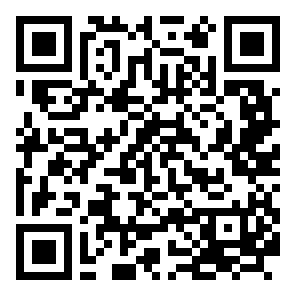

📱 Escanea el código con tu celular, o abre el link: **[Responder la encuesta](https://duoc.libwizard.com/f/encuesta_taller_bibliotecas_duoc)**

---
---

# 🎯 Desafíos propuestos

Para practicar después del taller. Cada uno tiene una **comprobación automática**: sabrás al
instante si lo resolviste. Necesitas haber ejecutado el notebook completo (Pasos 1 a 9).

| | Desafío | Qué practicas |
|---|---|---|
| 1 | `horario_biblioteca(dia, hora)` | Escribir una herramienta con validación de entradas |
| 2 | Una pregunta que use 3 herramientas | Encadenamiento y lectura de la traza |
| 3 | Rompe la descripción | El *docstring* como contrato |

### 🎯 Desafío 1 · `horario_biblioteca`

Escribe una herramienta que diga si la biblioteca está **abierta** o **cerrada** un día y a
una hora. Horario (del reglamento de ejemplo): **lunes a viernes de 08:30 a 21:00**,
**sábados de 09:00 a 14:00**, **domingo cerrado**.

- Recibe `dia` (`"lunes"` … `"domingo"`, con o sin tilde ni mayúsculas) y `hora` opcional (`"HH:MM"`).
- Devuelve un texto que diga **«abierta»** o **«cerrada»**. A la hora exacta de cierre ya está cerrada.
- Si el día o la hora vienen mal escritos, **devuelve un mensaje**: no lances excepciones.
- Escribe un *docstring* que diga **cuándo** usarla.

In [ ]:
# ▶ DESAFÍO 1 · Escribe la herramienta horario_biblioteca.
@tool
def horario_biblioteca(dia: str, hora: str = "") -> str:
    """TODO: escribe aquí CUÁNDO debe usarla el agente."""
    # TODO 1: normaliza el día (minúsculas, sin tildes: "Sábado" → "sabado"). Pista: _normalizar(dia)
    # TODO 2: busca el horario del día en un diccionario. Domingo: cerrada.
    # TODO 3: si viene una hora "HH:MM", di si a esa hora está ABIERTA o CERRADA.
    #         Si la hora viene mal escrita, devuelve un mensaje (no lances excepción).
    return "TODO"


print(horario_biblioteca.invoke({"dia": "sábado", "hora": "10:00"}))

In [ ]:
# ▶ DESAFÍO 1 · Comprobación automática. Ejecútala.
def comprobar_horario():
    casos = [  # (día, hora, debe decir, descripción)
        ("sábado", "10:00", "abierta", "sábado en la mañana"),
        ("Sabado", "15:00", "cerrada", "sábado en la tarde (y sin tilde)"),
        ("domingo", "", "cerrada", "domingo"),
        ("lunes", "08:00", "cerrada", "lunes antes de abrir"),
        ("miércoles", "20:59", "abierta", "miércoles justo antes de cerrar"),
        ("viernes", "21:00", "cerrada", "viernes a la hora de cierre"),
    ]
    ok = True
    for dia, hora, esperado, caso in casos:
        try:
            r = str(horario_biblioteca.invoke({"dia": dia, "hora": hora}))
        except Exception as e:
            r = f"EXCEPCIÓN {type(e).__name__}: {e}"
        bajo = r.lower()
        contrario = "cerrad" if esperado == "abierta" else "abiert"
        bien = esperado[:-1] in bajo and contrario not in bajo
        ok &= bien
        print("✅" if bien else "❌", f"{caso}: {dia} {hora or '(sin hora)'} →", r)
    for dia, hora in [("lunes", "25:99"), ("feriado", "")]:
        try:
            r = str(horario_biblioteca.invoke({"dia": dia, "hora": hora}))
            print("✅", f"Entrada rara ({dia} {hora}) → no rompe:", r)
        except Exception as e:
            ok = False
            print("❌", f"Entrada rara ({dia} {hora}) → lanzó {type(e).__name__} (debería devolver un mensaje)")
    if "TODO" in (horario_biblioteca.description or "TODO"):
        ok = False
        print("❌ Falta el docstring: el modelo no sabrá cuándo usarla.")
    print("\n🎉 ¡Desafío 1 listo!" if ok else "\n🔁 Revisa los ❌ y vuelve a ejecutar.")


comprobar_horario()

### 🎯 Desafío 2 · Una pregunta, tres herramientas

Arma un agente con las **cuatro** herramientas (las tres del taller y tu `horario_biblioteca`)
y escribe **una sola pregunta** que lo obligue a usar **al menos tres distintas**. Mira la
traza: ¿en qué orden las usó y por qué?

In [ ]:
# ▶ DESAFÍO 2 · Un agente con las cuatro herramientas y UNA pregunta que use al menos tres.
agente_completo = create_agent(modelo, tools=[calcular_multa, dias_de_atraso, buscar_libro, horario_biblioteca],
                               system_prompt=INSTRUCCIONES)

MI_PREGUNTA = "TODO: escribe una sola pregunta que obligue al agente a usar al menos 3 herramientas."

if "TODO" in MI_PREGUNTA:
    conversacion = []
    print("✏️  Escribe tu pregunta en MI_PREGUNTA y vuelve a ejecutar (así no gastas cupo).")
else:
    conversacion = ejecutar(agente_completo, MI_PREGUNTA)

In [ ]:
# ▶ DESAFÍO 2 · Comprobación. Ejecútala después de la celda anterior.
usadas = [t["name"] for m in conversacion if isinstance(m, AIMessage) for t in m.tool_calls]
distintas = sorted(set(usadas))
print("Herramientas usadas:", " → ".join(usadas) or "ninguna")
if "TODO" in MI_PREGUNTA:
    print("❌ Todavía no escribes tu pregunta.")
elif len(distintas) >= 3:
    print(f"🎉 ¡Desafío 2 listo! Usó {len(distintas)} herramientas distintas: {', '.join(distintas)}.")
else:
    print(f"🔁 Usó {len(distintas)} herramienta(s) distinta(s). Reformula la pregunta para que necesite más datos.")

### 🎯 Desafío 3 · Rompe la descripción (reflexión, sin comprobación)

1. Copia `dias_de_atraso` del Paso 9.1 y cámbiale el *docstring* por algo vago: `"""Hace cálculos."""`.
2. Arma de nuevo el agente del Paso 9.2 y repite la pregunta. ¿La sigue usando? ¿Calcula los días de cabeza?
3. Ahora pon la tarifa (`$300 por día`) **dentro** del *docstring* de `calcular_multa`. ¿El agente sigue llamándola?

Escribe en una celda de texto **dos o tres frases** con lo que observaste. Pista: el
*docstring* es el **contrato** entre el lenguaje humano y tu código.